# Lab 4 – Regularization, custom layers, multi-output models, ensembles and adversarial examples

In [3]:
import tensorflow as tf
from tensorflow import keras
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

In [4]:
# Task 1
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.mnist.load_data()
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0
X_train, X_valid = X_train_full[:-5000], X_train_full[-5000:]
y_train, y_valid = y_train_full[:-5000], y_train_full[-5000:]

In [5]:
def build_regularized_mnist_model():
    model = keras.models.Sequential()
    model.add(keras.Input(shape=(28, 28)))
    model.add(keras.layers.Flatten())
    model.add(keras.layers.Dense(300, activation="relu",
                                 kernel_regularizer=keras.regularizers.l1_l2(l1=0.001, l2=0.001),
                                 kernel_constraint=keras.constraints.MaxNorm(1.)))
    model.add(keras.layers.Dropout(rate=0.2))
    model.add(keras.layers.Dense(100, activation="relu",
                                 kernel_regularizer=keras.regularizers.l1_l2(l1=0.001, l2=0.001),
                                 kernel_constraint=keras.constraints.MaxNorm(1.)))
    model.add(keras.layers.Dropout(rate=0.2))

    model.add(keras.layers.Dense(10, activation="softmax"))
    
    return model

In [6]:
model = build_regularized_mnist_model()
optimizer = keras.optimizers.SGD(learning_rate=0.01) # 
model.compile(loss="sparse_categorical_crossentropy", optimizer=optimizer, metrics=["accuracy"])
history = model.fit(X_train, y_train, epochs=10, 
                    validation_data=(X_valid, y_valid))
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {test_acc:.4f}")

Epoch 1/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.7697 - loss: 7.7901 - val_accuracy: 0.9246 - val_loss: 5.3088
Epoch 2/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8740 - loss: 3.9511 - val_accuracy: 0.9296 - val_loss: 2.5692
Epoch 3/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8759 - loss: 1.9755 - val_accuracy: 0.9198 - val_loss: 1.3275
Epoch 4/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8745 - loss: 1.2585 - val_accuracy: 0.9260 - val_loss: 0.9853
Epoch 5/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8783 - loss: 1.0492 - val_accuracy: 0.9302 - val_loss: 0.8434
Epoch 6/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8786 - loss: 0.9385 - val_accuracy: 0.9368 - val_loss: 0.7523
Epoch 7/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8867 - loss: 0.8661 - val_accuracy: 0.9372 - val_loss: 0.6931
Epoch 8/10
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8899 - loss: 0.8133 - 

In [7]:
dataset, info = tfds.load("tf_flowers", as_supervised=True, with_info=True)
dataset_size = info.splits["train"].num_examples
n_classes = info.features["label"].num_classes

In [10]:
train_size = int(0.8 * dataset_size)
train_set = dataset["train"].take(train_size)
valid_set = dataset["train"].skip(train_size)
IMG_SIZE = 150 
BATCH_SIZE = 32
def preprocess(image, label):
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return image, label
train_set = train_set.map(preprocess).shuffle(1000).batch(BATCH_SIZE).prefetch(1)
valid_set = valid_set.map(preprocess).batch(BATCH_SIZE).prefetch(1)

In [11]:
class CustomAugmentation(keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
    def call(self, inputs, training=None):
        if training:
            return tf.image.random_brightness(inputs, max_delta=0.2)
        else:
            return inputs
            
model = keras.Sequential([

    keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    keras.layers.Rescaling(1./255),               
    keras.layers.RandomFlip("horizontal"),        
    keras.layers.RandomRotation(0.2),            
    CustomAugmentation(),                        
    keras.layers.Conv2D(32, kernel_size=3, activation="relu", padding="same"),
    keras.layers.MaxPooling2D(pool_size=2),
    keras.layers.Conv2D(64, kernel_size=3, activation="relu", padding="same"),
    keras.layers.MaxPooling2D(pool_size=2),
    keras.layers.Flatten(),
    
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.5), 
    keras.layers.Dense(n_classes, activation="softmax") 
])
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam",
              metrics=["accuracy"])
history = model.fit(train_set, epochs=10, validation_data=valid_set)

Epoch 1/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 142ms/step - accuracy: 0.3590 - loss: 1.5270 - val_accuracy: 0.4700 - val_loss: 1.2249
Epoch 2/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 14s 153ms/step - accuracy: 0.4700 - loss: 1.2616 - val_accuracy: 0.5286 - val_loss: 1.1524
Epoch 3/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 143ms/step - accuracy: 0.5187 - loss: 1.2175 - val_accuracy: 0.5559 - val_loss: 1.0622
Epoch 4/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 139ms/step - accuracy: 0.5419 - loss: 1.1346 - val_accuracy: 0.6417 - val_loss: 0.9674
Epoch 5/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 135ms/step - accuracy: 0.5579 - loss: 1.1067 - val_accuracy: 0.6049 - val_loss: 0.9445
Epoch 6/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 134ms/step - accuracy: 0.5937 - loss: 1.0457 - val_accuracy: 0.6063 - val_loss: 0.9667
Epoch 7/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 12s 135ms/step - accuracy: 0.5943 - loss: 1.0174 - val_accuracy: 0.6185 - val_loss: 0.9122
Epoch 8/10
92/92 ━━━━━━━━━━━━━━━━━━━━ 13s 137ms/step - accuracy: 0.6052 - loss: 1.0037 - val_accu

In [13]:
# Task 3
import numpy as np
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.cifar10.load_data()
X_train_full = X_train_full.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0
def create_binary_labels(y):
    y_bin = np.isin(y, [2, 3, 4, 5, 6, 7]).astype(int)
    return y_bin
y_train_bin = create_binary_labels(y_train_full)
y_test_bin = create_binary_labels(y_test)
inputs = keras.Input(shape=(32, 32, 3), name="image_input")

In [14]:
x = keras.layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
x = keras.layers.MaxPooling2D((2, 2))(x)
x = keras.layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
x = keras.layers.MaxPooling2D((2, 2))(x)
x = keras.layers.Flatten()(x)
shared_dense = keras.layers.Dense(128, activation='relu')(x)

In [ ]:
class_output = keras.layers.Dense(10, activation='softmax', name='class_output')(shared_dense)
binary_output = keras.layers.Dense(1, activation='sigmoid', name='binary_output')(shared_dense)
model = keras.Model(inputs=inputs, outputs=[class_output, binary_output])

In [ ]:
model.compile(optimizer='adam',
              loss={
                  'class_output': 'sparse_categorical_crossentropy',
                  'binary_output': 'binary_crossentropy'
              },
              loss_weights={ 
                  'class_output': 1.0,  
                  'binary_output': 1.0
              },
              metrics={'class_output': 'accuracy', 'binary_output': 'accuracy'})
history = model.fit(X_train_full, 
                    {'class_output': y_train_full, 'binary_output': y_train_bin},
                    validation_data=(X_test, {'class_output': y_test, 'binary_output': y_test_bin}),
                    epochs=10, 
                    batch_size=64)
results = model.evaluate(X_test, {'class_output': y_test, 'binary_output': y_test_bin}, return_dict=True)
for name, value in results.items():
    print(f"{name}: {value:.4f}")


In [15]:
#Task 4
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from tensorflow import keras
import matplotlib.pyplot as plt

In [16]:
X, y = make_blobs(n_samples=1000, centers=3, n_features=2, cluster_std=2.5, random_state=42)
df_X = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])
df_y = pd.DataFrame(y, columns=['Label'])
y_categorical = keras.utils.to_categorical(df_y['Label'])
X_train, X_test, y_train, y_test = train_test_split(df_X.values, y_categorical, test_size=0.3, random_state=42)
y_test_labels = np.argmax(y_test, axis=1)
def build_base_model():
    model = keras.Sequential([
        keras.layers.Dense(15, input_dim=2, activation='relu'),
        keras.layers.Dense(3, activation='softmax') 
    ])
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

In [21]:
def train_ensemble(n_models, X_train, y_train):
    ensemble_models = []
    for i in range(n_models):
        indices = np.random.choice(X_train.shape[0], size=X_train.shape[0], replace=True)
        X_sample = X_train[indices]
        y_sample = y_train[indices]
        model = build_base_model()
        model.fit(X_sample, y_sample, epochs=50, verbose=0)
        ensemble_models.append(model)
    return ensemble_models
def ensemble_predict(ensemble_models, X_test):
    predictions = [model.predict(X_test, verbose=0) for model in ensemble_models]
    predictions = np.array(predictions)
    summed_predictions = np.sum(predictions, axis=0)
    final_predictions = np.argmax(summed_predictions, axis=1)
    return final_predictions

In [20]:
def evaluate_ensemble(n_models, X_train, y_train, X_test, y_test_labels):
    ensemble_models = train_ensemble(n_models, X_train, y_train)
    y_pred = ensemble_predict(ensemble_models, X_test)
    score = accuracy_score(y_test_labels, y_pred)
    return score
n_members_list = [1, 2, 3, 5, 8, 12] 
scores = []

for n in n_members_list:
    score = evaluate_ensemble(n, X_train, y_train, X_test, y_test_labels)
    scores.append(score)
    print(f"{n:>2} Ensemble Score: {score:.4f}")

 1 Ensemble Score: 0.9867


 2 Ensemble Score: 0.9867


 3 Ensemble Score: 0.9867


 5 Ensemble Score: 0.9833


 8 Ensemble Score: 0.9867


12 Ensemble Score: 0.9867


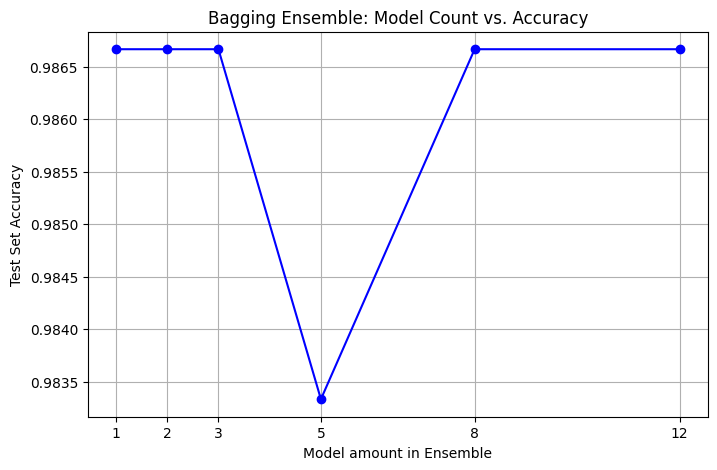

In [23]:
plt.figure(figsize=(8, 5))
plt.plot(n_members_list, scores, marker='o', linestyle='-', color='b')
plt.title('Bagging Ensemble: Model Count vs. Accuracy')
plt.xlabel('Model amount in Ensemble')
plt.ylabel('Test Set Accuracy')
plt.xticks(n_members_list)
plt.grid(True)
plt.show()

In [28]:
# Task 5
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0
y_train_cat = keras.utils.to_categorical(y_train, 10)
y_test_cat = keras.utils.to_categorical(y_test, 10)
classifier = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')])

classifier.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [30]:
classifier.fit(X_train, y_train_cat, epochs=3, batch_size=128, verbose=0)
sample_idx = 0
image = X_test[sample_idx]
true_class = y_test[sample_idx]

In [31]:
random_noise = np.random.normal(loc=0.0, scale=0.5, size=(28, 28))
noisy_image = np.clip(image + random_noise, 0., 1.)
image_batch = np.expand_dims(image, axis=0)
noisy_image_batch = np.expand_dims(noisy_image, axis=0)
pred_original = np.argmax(classifier.predict(image_batch, verbose=0))
pred_noisy = np.argmax(classifier.predict(noisy_image_batch, verbose=0))

In [ ]:
print(f"\n2. Original Image Prediction: Class {pred_original} (True Class: {true_class})")
print(f"Randomly Noisy Image Prediction: Class {pred_noisy}")
classifier.trainable = False
image_input = keras.Input(shape=(28, 28), name="image_input")
unity_input = keras.Input(shape=(1,), name="unity_input")

In [ ]:
noise_layer = keras.layers.Dense(28*28, use_bias=False, 
                                 kernel_regularizer=keras.regularizers.l2(0.01),
                                 name="adversarial_noise")(unity_input)
reshaped_noise = keras.layers.Reshape((28, 28))(noise_layer)
augmented_image = keras.layers.Add()([image_input, reshaped_noise])
def clip_activation(x):
    return tf.clip_by_value(x, 0.0, 1.0)
clipped_image = keras.layers.Activation(clip_activation)(augmented_image)
output = classifier(clipped_image)
adv_model = keras.Model(inputs=[image_input, unity_input], outputs=output)

In [ ]:
def negative_categorical_crossentropy(y_true, y_pred):
    return -keras.losses.categorical_crossentropy(y_true, y_pred)
adv_model.compile(loss=negative_categorical_crossentropy, optimizer=keras.optimizers.Adam(learning_rate=0.05))
unity_val = np.array([[1.0]])
true_class_onehot = np.expand_dims(y_test_cat[sample_idx], axis=0)
adv_model.fit({'image_input': image_batch, 'unity_input': unity_val}, 
              true_class_onehot, 
              epochs=50, verbose=0)
noise_extractor = keras.Model(inputs=adv_model.inputs, outputs=adv_model.get_layer("activation").output)
adv_image = noise_extractor.predict({'image_input': image_batch, 'unity_input': unity_val}, verbose=0)
pred_adv = np.argmax(classifier.predict(adv_image, verbose=0))
print(f"Adversarial Attack Result: Class {pred_adv} (True Class: {true_class})")

In [ ]:
plt.figure(figsize=(10, 3))
plt.subplot(1, 3, 1)
plt.title(f"Original\nPrediction: {pred_original}")
plt.imshow(image, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.title(f"Random Noise\nPrediction: {pred_noisy}")
plt.imshow(noisy_image, cmap='gray')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.title(f"Adversarial Noise\nPrediction: {pred_adv}")
plt.imshow(adv_image[0], cmap='gray')
plt.axis('off')

plt.tight_layout()
plt.show()